# Homework 7 Wang Jiayan

# Simulating Bursty Gene Expression

##  Model and Parameters

The aim of this notebook is to simulate transcriptional bursting using the
Gillespie stochastic simulation algorithm (SSA), visualize single-cell
trajectories, and compare the steady-state mRNA distribution with Poisson
and negative binomial distributions.

The state of one cell is described by:

- $s \in \{0,1\}$: promoter state, where 0 represents OFF and 1 represents ON;
- $m$: number of mRNA molecules;
- $p$: number of protein molecules.

The model contains the following reactions:

| Reaction | State change | Propensity |
|---|---|---|
| Promoter activation | $s:0\rightarrow1$ | $k_{\mathrm{on}}(1-s)$ |
| Promoter inactivation | $s:1\rightarrow0$ | $k_{\mathrm{off}}s$ |
| Transcription | $m\rightarrow m+1$ | $\beta s$ |
| mRNA degradation | $m\rightarrow m-1$ | $\gamma m$ |
| Translation, optional | $p\rightarrow p+1$ | $k_t m$ |
| Protein degradation, optional | $p\rightarrow p-1$ | $\gamma_p p$ |

Transcription occurs only when the promoter is ON. However, mRNA
degradation and translation can occur in either promoter state.
Translation does not consume mRNA.

We assume one promoter per cell, constant reaction rates, and no feedback,
cell division, or variation in parameters between cells. All times are
measured in minutes. The parameters are illustrative rather than fitted
to experimental data.

The mean OFF and ON durations are:

$$
\langle T_{\mathrm{OFF}}\rangle = \frac{1}{k_{\mathrm{on}}},
\qquad
\langle T_{\mathrm{ON}}\rangle = \frac{1}{k_{\mathrm{off}}}.
$$

The expected number of transcripts produced during one ON episode is:

$$
b = \frac{\beta}{k_{\mathrm{off}}}.
$$

For the selected parameters, the promoter remains OFF for an average of
10 minutes and ON for an average of 0.2 minutes, producing approximately
10 transcripts per ON episode. These short periods of rapid transcription
generate bursts of mRNA production.

In [1]:
# If needed, uncomment and run once:
# %pip install numpy scipy matplotlib

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson, nbinom

params = {
    "k_on": 0.1,       # Promoter activation rate, min^-1
    "k_off": 5.0,      # Promoter inactivation rate, min^-1
    "beta": 50.0,      # Transcription rate while ON, transcripts/min
    "gamma": 0.2,      # Degradation rate per mRNA, min^-1
    "k_t": 1.0,        # Translation rate per mRNA, proteins/min
    "gamma_p": 0.04,   # Degradation rate per protein, min^-1
}

print(f"Mean OFF duration: {1 / params['k_on']:.2f} min")
print(f"Mean ON duration: {1 / params['k_off']:.2f} min")
print(f"Mean transcripts per ON episode: "
      f"{params['beta'] / params['k_off']:.2f}")

Mean OFF duration: 10.00 min
Mean ON duration: 0.20 min
Mean transcripts per ON episode: 10.00


In [7]:
def simulate_ssa(
    params, t_end, rng, include_protein=False, record=True
):
    """Simulate one cell, initially OFF with zero mRNA and protein."""
    t = 0.0
    s, m, p = 0, 0, 0

    if record:
        times = [t]
        states = [(s, m, p)]

    while t < t_end:
        rates = np.array([
            params["k_on"] * (1 - s),
            params["k_off"] * s,
            params["beta"] * s,
            params["gamma"] * m,
            params["k_t"] * m if include_protein else 0.0,
            params["gamma_p"] * p if include_protein else 0.0,
        ])

        total_rate = rates.sum()

        # No reaction can occur in an absorbing state.
        if total_rate == 0:
            break

        next_t = t + rng.exponential(1 / total_rate)

        # Do not apply a reaction beyond the observation time.
        if next_t > t_end:
            break

        reaction = np.searchsorted(
            np.cumsum(rates),
            rng.random() * total_rate,
            side="right",
        )

        if reaction == 0:
            s = 1
        elif reaction == 1:
            s = 0
        elif reaction == 2:
            m += 1
        elif reaction == 3:
            m -= 1
        elif reaction == 4:
            p += 1
        else:
            p -= 1

        t = next_t

        if record:
            times.append(t)
            states.append((s, m, p))

    if record:
        # Extend the final state to the requested observation time.
        times.append(float(t_end))
        states.append((s, m, p))
        return np.asarray(times), np.asarray(states, dtype=int)

    return np.array([s, m, p], dtype=int)

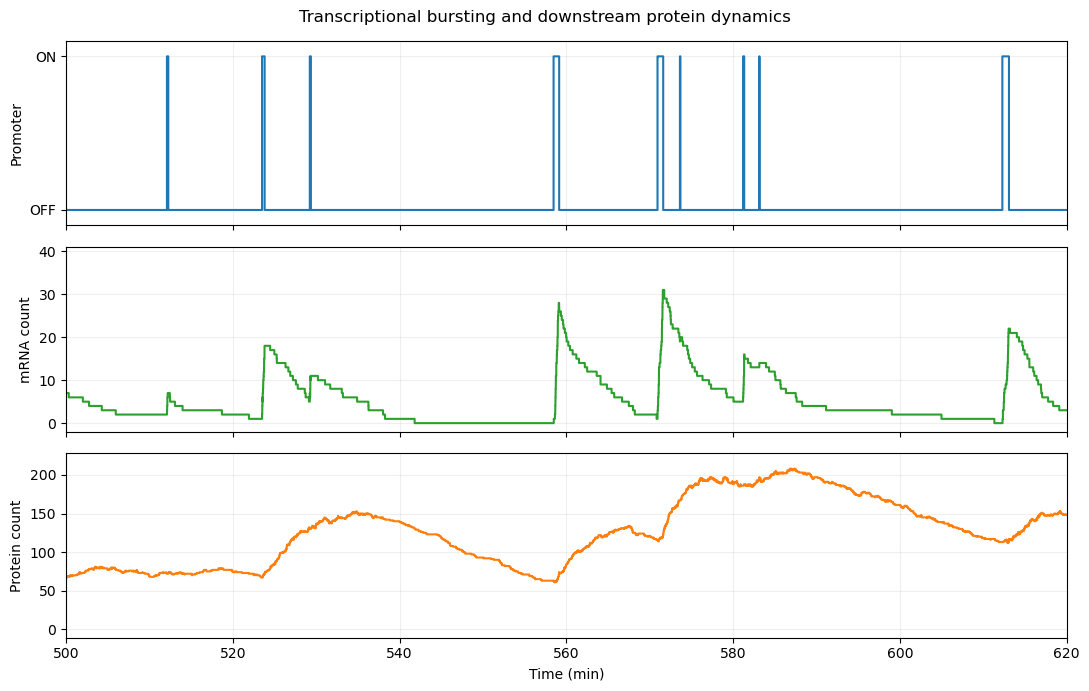

In [3]:
switch_sum = params["k_on"] + params["k_off"]

trace_burn_in = 20 * max(
    1 / params["gamma"],
    1 / switch_sum,
    1 / params["gamma_p"],
)
view_duration = 120.0

times, states = simulate_ssa(
    params,
    t_end=trace_burn_in + view_duration,
    rng=np.random.default_rng(42),
    include_protein=True,
)

fig, axes = plt.subplots(
    3, 1, figsize=(11, 7), sharex=True
)

axes[0].step(
    times, states[:, 0], where="post", color="tab:blue"
)
axes[0].set_yticks([0, 1], labels=["OFF", "ON"])
axes[0].set_ylim(-0.1, 1.1)
axes[0].set_ylabel("Promoter")

axes[1].step(
    times, states[:, 1], where="post", color="tab:green"
)
axes[1].set_ylabel("mRNA count")

axes[2].step(
    times, states[:, 2], where="post", color="tab:orange"
)
axes[2].set_ylabel("Protein count")
axes[2].set_xlabel("Time (min)")
axes[2].set_xlim(
    trace_burn_in, trace_burn_in + view_duration
)

for ax in axes:
    ax.grid(alpha=0.2)

fig.suptitle(
    "Transcriptional bursting and downstream protein dynamics"
)
fig.tight_layout()
plt.show()

In [4]:
mean_theory = (
    params["beta"] / params["gamma"]
    * params["k_on"] / switch_sum
)

fano_theory = 1 + (
    params["beta"] * params["k_off"]
    / (
        switch_sum
        * (params["gamma"] + switch_sum)
    )
)

var_theory = mean_theory * fano_theory

# Use 20 times the slower of the two mRNA relaxation times.
burn_in = 20 * max(
    1 / params["gamma"],
    1 / switch_sum,
)

n_cells = 3000
rng_population = np.random.default_rng(2026)

final_states = np.array([
    simulate_ssa(
        params,
        t_end=burn_in,
        rng=rng_population,
        include_protein=False,
        record=False,
    )
    for _ in range(n_cells)
])

samples = final_states[:, 1]

sample_mean = samples.mean()
sample_var = samples.var(ddof=1)
sample_fano = sample_var / sample_mean

print(f"Number of independent cells: {n_cells}")
print(f"Burn-in time: {burn_in:.1f} min")
print()
print(f"{'Statistic':<15}{'Simulation':>14}{'Theory':>14}")

for name, observed, expected in [
    ("Mean", sample_mean, mean_theory),
    ("Variance", sample_var, var_theory),
    ("Fano factor", sample_fano, fano_theory),
]:
    print(f"{name:<15}{observed:>14.3f}{expected:>14.3f}")

Number of independent cells: 3000
Burn-in time: 100.0 min

Statistic          Simulation        Theory
Mean                    4.937         4.902
Variance               49.483        50.240
Fano factor            10.022        10.249
